# 01 - Exploratory Data Analysis & Data Preprocessing

**Dataset:** Cricsheet IPL ball-by-ball data (CSV2 format), https://cricsheet.org - licensed under the Open Data
Commons Attribution License (ODC-By 1.0). Download it with `python -m src.data_loader --download`.

This notebook inspects the **real** dataset, explains the cleaning rules, and shows why some matches are excluded
from model training. All logic lives in `src/` so the notebook, the training script and the app share one
implementation.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 1. Load the raw data and inspect its schema

`load_raw_data()` detects the dataset format (Cricsheet CSV2 or Kaggle-style `matches.csv` + `deliveries.csv`),
checks that the required columns exist, and converts it to one canonical schema.

In [2]:
from src.eda import load_for_eda, overview, missing_values, team_stats, season_stats, outcome_distribution
d = load_for_eda()
print("Raw deliveries columns:", list(d["raw_deliveries"].columns))
print("Raw matches columns:   ", list(d["raw_matches"].columns))
d["raw_deliveries"].head()

2026-10-27 23:55:08,681 | INFO | src.data_loader | Detected cricsheet dataset at C:\Users\Vatsal Ghori\Desktop\IPL-Win-Probability\data\raw\cricsheet_ipl_csv2


Raw deliveries columns: ['match_id', 'innings', 'over', 'ball_label', 'seq', 'batting_team', 'bowling_team', 'runs_off_bat', 'extras', 'is_wide', 'is_noball', 'wickets']
Raw matches columns:    ['match_id', 'season', 'date', 'venue', 'city', 'team1', 'team2', 'winner', 'outcome', 'method', 'eliminator', 'target_runs', 'target_overs', 'scheduled_overs']


,match_id,innings,over,ball_label,seq,batting_team,bowling_team,runs_off_bat,extras,is_wide,is_noball,wickets
0,1082591,1,0,0.1,0,Sunrisers Hyderabad,Royal Challengers Bangalore,0,0,False,False,0
1,1082591,1,0,0.2,1,Sunrisers Hyderabad,Royal Challengers Bangalore,0,0,False,False,0
2,1082591,1,0,0.3,2,Sunrisers Hyderabad,Royal Challengers Bangalore,4,0,False,False,0
3,1082591,1,0,0.4,3,Sunrisers Hyderabad,Royal Challengers Bangalore,0,0,False,False,0
4,1082591,1,0,0.5,4,Sunrisers Hyderabad,Royal Challengers Bangalore,0,2,True,False,0


In [3]:
pd.Series(overview(d), name="value").to_frame()

,value
matches,1243
deliveries_all_innings,295732
deliveries_regulation_innings,295557
super_over_deliveries,175
seasons,2008-2026 (19 seasons)
teams_after_normalisation,15
venues_after_normalisation,37
duplicate_deliveries,0
duplicate_match_ids,0
total_runs,401423


## 2. Missing values and duplicates

* `winner` is missing only for no-results and ties (the tie winner is in `eliminator`, decided by a super over).
* `method` is set only for D/L (rain-affected) matches.
* There are no duplicate deliveries or duplicate match ids (the pipeline would drop them if there were).

In [4]:
display(missing_values(d))
print("Duplicate deliveries:", d["raw_deliveries"].duplicated(["match_id", "innings", "ball_label"]).sum())
print("Duplicate match ids: ", d["raw_matches"]["match_id"].duplicated().sum())

,missing,pct
eliminator,1227,98.7
method,1220,98.1
winner,25,2.0
target_runs,6,0.5
target_overs,6,0.5


Duplicate deliveries: 0
Duplicate match ids:  0


## 3. Inconsistent team names

Several franchises were renamed (Delhi Daredevils -> Delhi Capitals, Kings XI Punjab -> Punjab Kings,
Royal Challengers Bangalore -> Royal Challengers Bengaluru). They are mapped to their current names so their
history is not split. Defunct franchises (Deccan Chargers, Kochi Tuskers Kerala, Pune Warriors, Gujarat Lions,
Rising Pune Supergiant) are distinct teams and kept separate.

In [5]:
raw_names = pd.concat([d["raw_matches"]["team1"], d["raw_matches"]["team2"]]).value_counts()
from src.utils import normalize_team
pd.DataFrame({"matches": raw_names, "normalised_to": raw_names.index.map(normalize_team)})

,matches,normalised_to
Mumbai Indians,291,Mumbai Indians
Kolkata Knight Riders,278,Kolkata Knight Riders
Chennai Super Kings,266,Chennai Super Kings
Rajasthan Royals,251,Rajasthan Royals
Royal Challengers Bangalore,240,Royal Challengers Bengaluru
Sunrisers Hyderabad,211,Sunrisers Hyderabad
Kings XI Punjab,190,Punjab Kings
Delhi Daredevils,161,Delhi Capitals
Delhi Capitals,120,Delhi Capitals
Punjab Kings,88,Punjab Kings


## 4. Seasons, runs and wickets

,matches,avg_first_innings,avg_wickets,chase_win_rate
season_year,,,,
2008,58,161.0,6.8,0.611
2009,57,150.3,6.5,0.528
2010,60,164.8,6.1,0.475
2011,73,152.4,5.9,0.536
2012,74,157.5,5.8,0.534
2013,76,155.9,5.9,0.507
2014,60,163.1,5.9,0.632
2015,59,166.3,5.8,0.423
2016,60,162.6,6.2,0.679


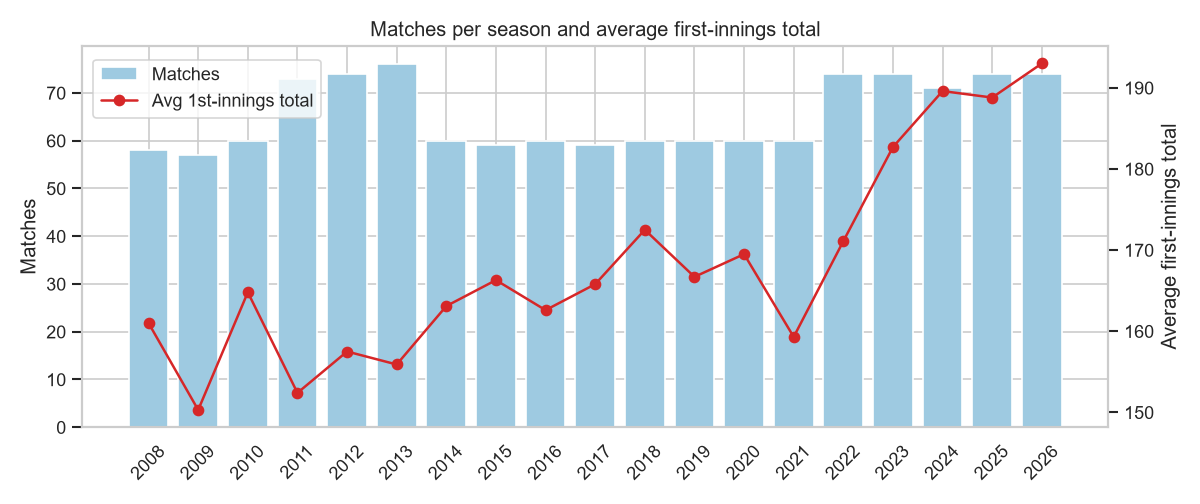

In [6]:
seasons = season_stats(d)
display(seasons)
display(Image(filename=str(ROOT / "artifacts/eda/season_matches_scores.png")))

Average first-innings totals jumped from roughly 160-170 to roughly 190 from 2023 onwards (the
"Impact Player" rule era). This **era shift** matters for modelling: a target of 190 was hard to chase in 2015
but is close to par today. Because we test on the most recent seasons, the test set measures how well a model
trained on older seasons carries over to the new era.

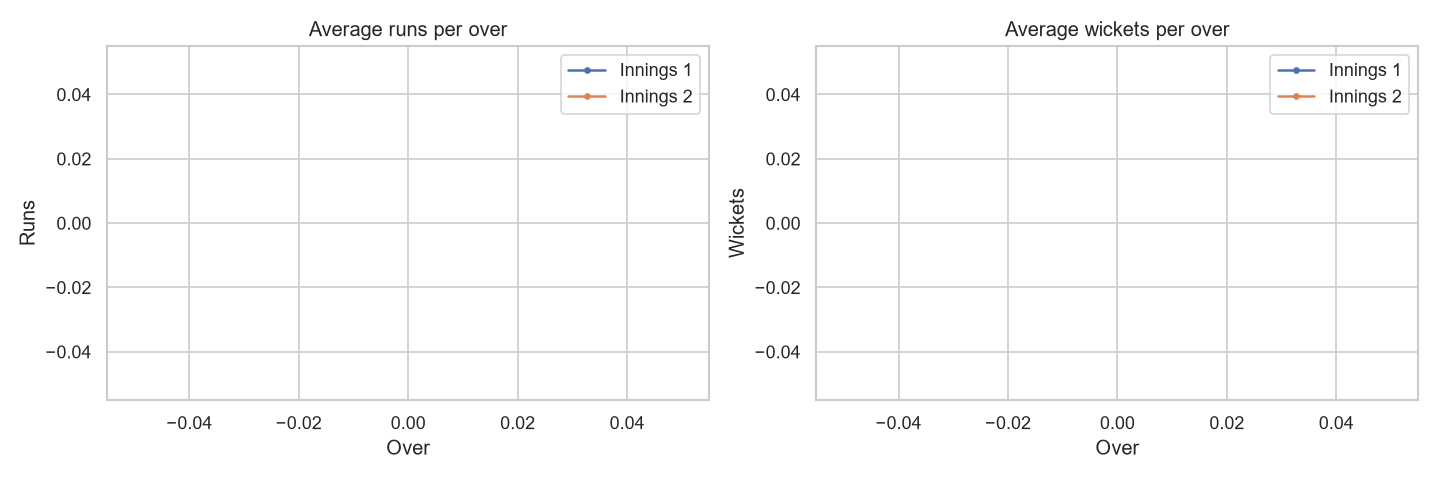

In [7]:
display(Image(filename=str(ROOT / "artifacts/eda/runs_wickets_by_over.png")))

Runs per over rise sharply in the death overs (16-20), and wickets cluster there too - so the same
"runs needed" means very different things depending on balls and wickets left. This motivates using
**runs left, balls left, wickets left and the required run rate together** as features.

## 5. Teams and match winners

,matches,wins,win_pct
Mumbai Indians,291,155,53.3
Royal Challengers Bengaluru,286,143,50.0
Delhi Capitals,281,125,44.5
Kolkata Knight Riders,278,140,50.4
Punjab Kings,278,126,45.3
Chennai Super Kings,266,148,55.6
Rajasthan Royals,251,123,49.0
Sunrisers Hyderabad,211,102,48.3
Gujarat Titans,77,47,61.0
Deccan Chargers,75,29,38.7


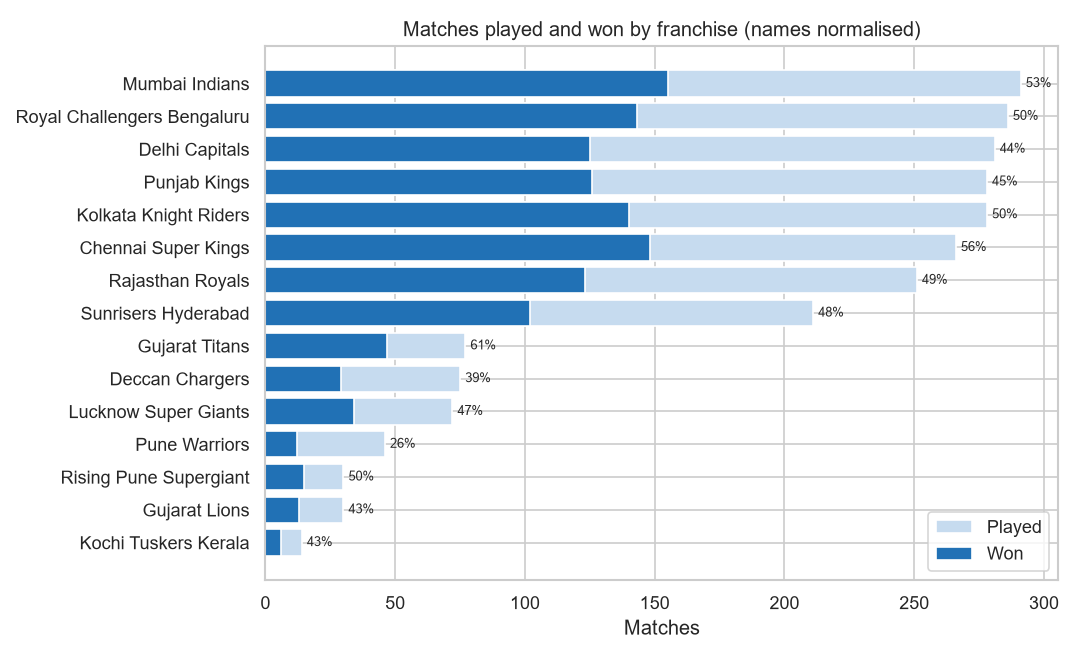

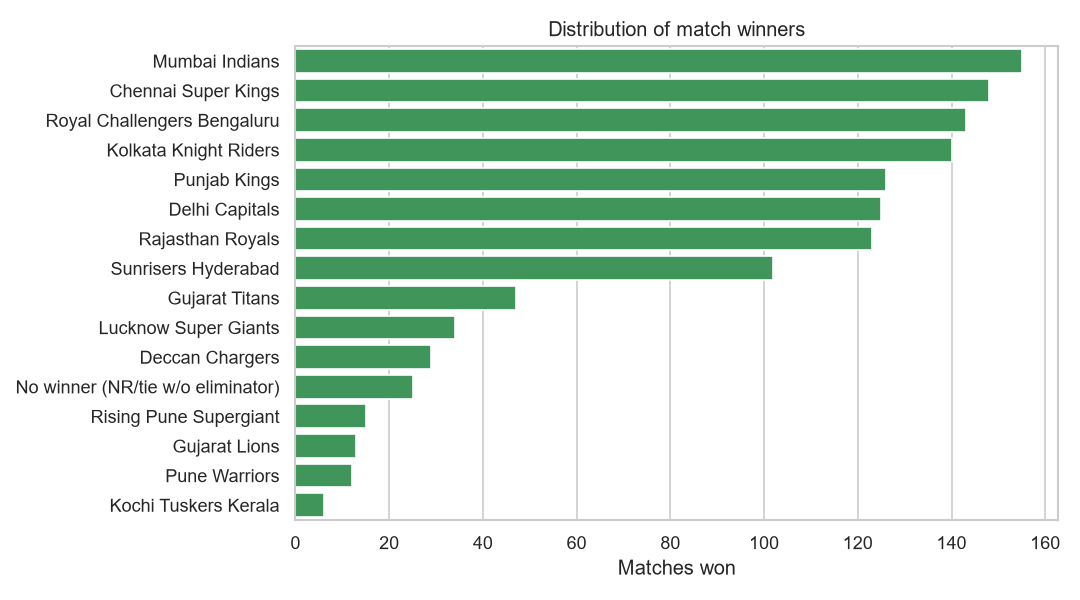

In [8]:
display(team_stats(d))
display(Image(filename=str(ROOT / "artifacts/eda/team_matches_wins.png")))
display(Image(filename=str(ROOT / "artifacts/eda/match_winners.png")))

## 6. Match outcomes, exclusions and class balance

The model predicts **"does the chasing team win?"**. That label is only well-defined for completed 20-over
chases, so matches are excluded when:

| Reason | Why |
|---|---|
| No result | Abandoned, no winner |
| Tie decided by super over | The regulation chase neither succeeded nor failed |
| D/L method / reduced overs | The target or available balls changed, breaking the 20-over state assumptions |
| Inconsistent metadata | Missing innings, winner contradicting the ball-by-ball totals, etc. |

,matches
Chasing team won,646
Defending team won,539
Excluded: D/L method applied,23
Excluded: tie decided by super over,16
Excluded: reduced-overs match,10
Excluded: no result / abandoned,9


,matches excluded
reason,
D/L method applied,23
tie decided by super over,16
reduced-overs match,10
no result / abandoned,9


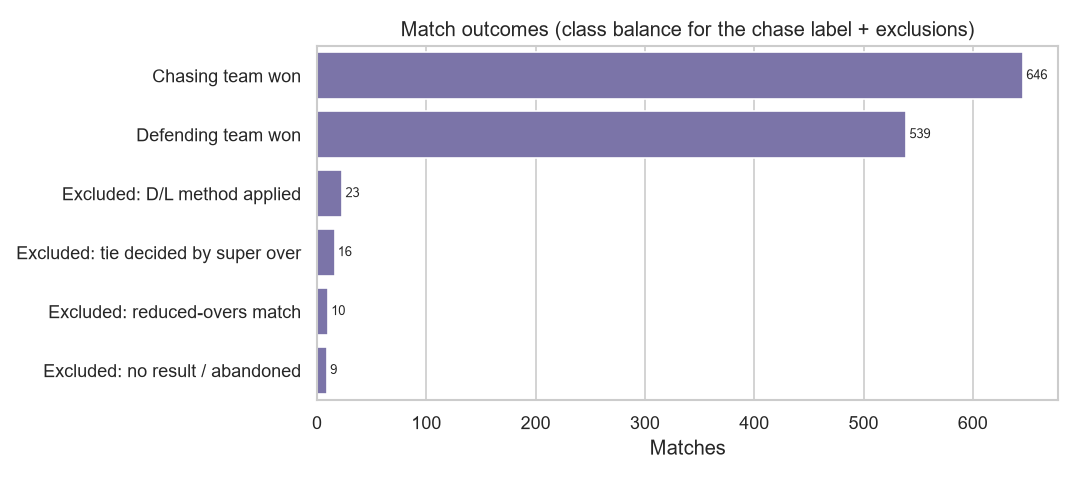

Chasing-team win rate (eligible matches): 0.545


In [9]:
display(outcome_distribution(d).to_frame("matches"))
display(d["excluded"]["reason"].value_counts().to_frame("matches excluded"))
display(Image(filename=str(ROOT / "artifacts/eda/match_outcomes.png")))
print(f"Chasing-team win rate (eligible matches): {d['clean']['chase_won'].mean():.3f}")

The classes are close to balanced (chasing sides win ~54-55% of eligible matches), so no re-sampling is
needed. We still evaluate with probability metrics (log loss, Brier) rather than accuracy alone.

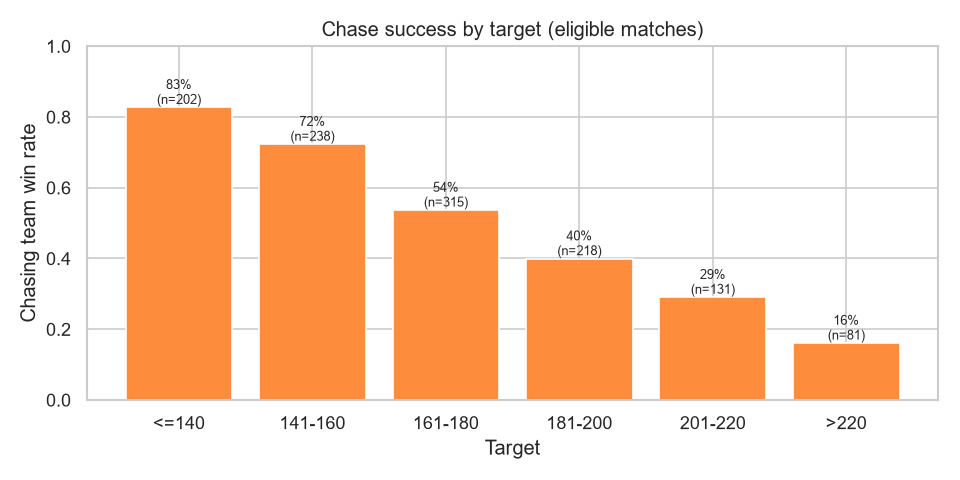

In [10]:
display(Image(filename=str(ROOT / "artifacts/eda/chase_success_by_target.png")))

## 7. From deliveries to match states (feature engineering)

Cricket rules used when accumulating the chase:

* **Legal deliveries:** wides and no-balls are re-bowled and do **not** count towards the 6 balls of an over;
  byes and leg-byes **do** count.
* **Runs:** every run counts towards the score - runs off the bat plus all extras.
* **Wickets:** every dismissal except *retired hurt* / *retired not out* counts towards the 10 wickets.
* **Target:** first-innings total + 1 (Cricsheet's recorded target is checked against this).

One row is produced **after every delivery** of the chase (plus the 0/0 starting state), using cumulative
totals up to that delivery only - so no future information leaks into features. Finished states (target reached,
all out, 20 overs bowled) are dropped because their outcome is already known.

In [11]:
from src.preprocessing import run_preprocessing
from src.feature_engineering import build_chase_states, FEATURE_COLUMNS
clean, deliveries, excluded = run_preprocessing(save=True)
states = build_chase_states(deliveries, clean)
print(f"{len(states):,} live chase states from {states['match_id'].nunique():,} matches")
print("Model features:", FEATURE_COLUMNS)
example = states[states["match_id"] == states["match_id"].iloc[-1]]
example[["balls_bowled", "current_score", "wickets_lost", "runs_left", "balls_left", "current_run_rate",
         "required_run_rate", "chase_won"]].iloc[::12]

2026-10-27 23:55:11,899 | INFO | src.data_loader | Detected cricsheet dataset at C:\Users\Vatsal Ghori\Desktop\IPL-Win-Probability\data\raw\cricsheet_ipl_csv2


2026-10-27 23:55:14,671 | INFO | src.preprocessing | Matches: 1243 raw -> 1185 eligible (58 excluded). Chasing-team win rate: 0.545


2026-10-27 23:55:14,674 | INFO | src.preprocessing | Exclusion reasons:
reason
D/L method applied           23
tie decided by super over    16
reduced-overs match          10
no result / abandoned         9


2026-10-27 23:55:16,740 | INFO | src.preprocessing | Saved cleaned data to C:\Users\Vatsal Ghori\Desktop\IPL-Win-Probability\data\processed


137,893 live chase states from 1,185 matches
Model features: ['batting_team', 'bowling_team', 'venue', 'target', 'current_score', 'runs_left', 'wickets_lost', 'wickets_left', 'balls_bowled', 'balls_left', 'current_run_rate', 'required_run_rate', 'impact_player_era']


,balls_bowled,current_score,wickets_lost,runs_left,balls_left,current_run_rate,required_run_rate,chase_won
137784,0,0,0,156,120,0.000000,7.800000,1
137796,12,23,0,133,108,11.500000,7.388889,1
137808,24,55,0,101,96,13.750000,6.312500,1
137820,36,70,2,86,84,11.666667,6.142857,1
137832,47,84,2,72,73,10.723404,5.917808,1
137844,59,100,4,56,61,10.169492,5.508197,1
137856,71,115,4,41,49,9.718310,5.020408,1
137868,83,132,4,24,37,9.542169,3.891892,1
137880,95,145,5,11,25,9.157895,2.640000,1
137892,107,155,5,1,13,8.691589,0.461538,1


Each match contributes ~100-125 highly correlated rows, so **train/test splits must be by match**
(never by row), and preferably chronological - which is exactly what `src/train.py` does
(see notebook 02).